# 1. Records with duplicate IDs

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import display

data_path = Path("../Final_Data.xlsx")
data = pd.read_excel(data_path, dtype={"listing_id": "string"})

duplicate_id_records = (
    data.loc[data["listing_id"].duplicated(keep=False)]
    .sort_values("listing_id")
)
print(f"Duplicate ID values: {duplicate_id_records['listing_id'].nunique():,}")
print(f"Records with duplicate IDs: {len(duplicate_id_records):,}")
display(duplicate_id_records.head(5))

Duplicate ID values: 7
Records with duplicate IDs: 14


,listing_id,listing_type,posted_date,expiry_date,property_type,city_province,district,Folder,title,address,...,near_park,river_view,park_view,city_view,balcony,garden,garage,terrace,frontage,access_road
493,41685836,Tin VIP Kim Cương,04/03/2026,11/03/2026,Nhà đất,Hồ Chí Minh,Phường Phú Thuận,Bán/Hồ Chí Minh/Phú Thuận/Nhà riêng tại đường ...,"Nhà phố hiện đại, xây dựng tâm huyết - Hẻm 41 ...","Đường Chuyên Dùng 9, Phường Phú Thuận, Hồ Chí ...",...,0,0,0,0,0,0,1,1,4.0,3.5
1880,41685836,Tin thường,04/03/2026,11/03/2026,Nhà đất,Hồ Chí Minh,Phường Phú Thuận,Bán/Hồ Chí Minh/Phú Thuận/Nhà riêng tại đường ...,"Nhà phố hiện đại, xây dựng tâm huyết - Hẻm 41 ...","Đường Chuyên Dùng 9, Phường Phú Thuận, Hồ Chí ...",...,0,0,0,0,0,0,1,1,4.0,3.5
491,44315816,Tin VIP Kim Cương,06/03/2026,13/03/2026,Nhà đất,Hồ Chí Minh,Xã Nhà Bè,Bán/Hồ Chí Minh/Nhà Bè/Nhà riêng tại đường Huỳ...,Nhà phố hiện đại - trẻ trung - NT cao cấp - lô...,"Đường Huỳnh Tấn Phát, Xã Nhà Bè, Hồ Chí Minh",...,0,0,0,0,0,0,0,0,NaN,3.0
1464,44315816,Tin thường,06/03/2026,13/03/2026,Nhà đất,Hồ Chí Minh,Xã Nhà Bè,Bán/Hồ Chí Minh/Nhà Bè/Nhà riêng tại đường Huỳ...,Nhà phố hiện đại - trẻ trung - NT cao cấp - lô...,"Đường Huỳnh Tấn Phát, Xã Nhà Bè, Hồ Chí Minh",...,0,0,0,0,0,0,0,0,NaN,3.0
490,44910264,Tin VIP Kim Cương,06/03/2026,13/03/2026,Nhà đất,Hồ Chí Minh,Phường Tân Hưng,Bán/Hồ Chí Minh/Tân Hưng/Nhà mặt phố tại phố T...,Nhà phố mặt tiền Trần Xuân Soạn vị trí đắc địa...,"Phố Trần Xuân Soạn, Phường Tân Hưng, Hồ Chí Minh",...,0,0,0,0,0,0,0,0,3.2,15.0


# 2. Records with coordinates outside HCMC

In [2]:
coordinates = data["latitude_longitude"].astype("string").str.extract(
    r"q?\s*=\s*([-+]?\d+(?:\.\d+)?)\s*,\s*([-+]?\d+(?:\.\d+)?)"
)
latitude = pd.to_numeric(coordinates[0], errors="coerce")
longitude = pd.to_numeric(coordinates[1], errors="coerce")
valid_coordinates = latitude.between(10.3, 11.6) & longitude.between(106.3, 107.6)

invalid_coordinate_records = data.loc[
    ~valid_coordinates, ["listing_id", "latitude_longitude", "district"]
].assign(latitude=latitude[~valid_coordinates], longitude=longitude[~valid_coordinates])

print(f"Records with invalid coordinates: {len(invalid_coordinate_records):,}")
display(invalid_coordinate_records.head(5))

Records with invalid coordinates: 43


,listing_id,latitude_longitude,district,latitude,longitude
6,45260467,"q=21.0289486097874,105.852447225903",Phường Hòa Hưng,21.028949,105.852447
10,45235016,"q=21.0289486097874,105.852447225903",Phường Đông Hưng Thuận,21.028949,105.852447
11,45232873,"q=21.0289486097874,105.852447225903",Phường Phú Thuận,21.028949,105.852447
33,45245173,"q=21.0289486097874,105.852447225903",Phường Sài Gòn,21.028949,105.852447
38,45246753,"q=21.0289486097874,105.852447225903",Phường Phú Thuận,21.028949,105.852447


# 3. Records with missing `bedrooms`

In [3]:
missing_bedrooms = data.loc[data["bedrooms"].isna()].copy()

print(
    f"Missing bedrooms: {len(missing_bedrooms):,} / {len(data):,} "
    f"({len(missing_bedrooms) / len(data):.2%})"
)
with pd.option_context("display.max_rows", len(missing_bedrooms), "display.max_columns", None):
    display(missing_bedrooms.head(5))

Missing bedrooms: 340 / 3,037 (11.20%)


,listing_id,listing_type,posted_date,expiry_date,property_type,city_province,district,Folder,title,address,old_address,location_link,latitude_longitude,description,area_price_history,price_range,area,bedrooms,bathrooms,legal_status,furnishing,balcony_direction,house_direction,pool,gym,park,bbq,kids_playground,sports_court,security_24h,reception,elevator,parking,near_metro,near_bus,near_highway,near_school,near_hospital,near_mall,near_market,near_park,river_view,park_view,city_view,balcony,garden,garage,terrace,frontage,access_road
36,44748012,Tin thường,09/03/2026,24/03/2026,Căn hộ,Hồ Chí Minh,Phường Long Bình,Bán/Hồ Chí Minh/Long Bình/Căn hộ chung cư tại ...,"Studio Rainbow view thoáng, S1.05 - 1310. Giá ...","The Rainbow - Vinhomes Grand Park, Đường Nguyễ...","Quận 9, Hồ Chí Minh cũ",https://www.google.com/maps/embed/v1/place?q=1...,"q=10.8374374908489,106.838813365258",Studio Rainbow view thoáng.\n\nS1.05 - 1310.\n...,19.6,1.87,27.9,NaN,NaN,Sổ hồng riêng,Đầy đủ,NaN,NaN,1,1,1,1,1,1,1,0,1,1,1,0,1,1,1,1,1,0,1,0,0,0,1,0,0,NaN,NaN
75,44732031,Tin thường,08/03/2026,23/03/2026,Căn hộ,Hồ Chí Minh,Phường Tân Bình,Bán/Hồ Chí Minh/Tân Bình/Căn hộ chung cư tại B...,Giảm 200tr - bán nhanh căn hộ chung cư Bàu Cát...,"Bàu Cát II, Đường Đồng Đen, Phường Tân Bình, H...","Quận Tân Bình, Hồ Chí Minh cũ",https://www.google.com/maps/embed/v1/place?q=1...,"q=10.7915953160349,106.643971598223","Vị trí: Đường Đồng Đen, P. 14, Tân Bình.\n\nDi...",25.1,1.80,26.8,NaN,1.0,Sổ hồng riêng,Không nội thất,NaN,NaN,0,1,1,0,0,0,1,0,1,1,0,0,0,1,1,0,1,0,0,0,0,0,0,0,0,NaN,NaN
91,44397902,Tin thường,09/03/2026,24/03/2026,Căn hộ,Hồ Chí Minh,Phường Long Bình,Bán/Hồ Chí Minh/Long Bình/Căn hộ chung cư tại ...,Bán căn Studio có ban công The Beverly - Vinho...,"The Beverly - Vinhomes Grand Park, Phường Long...","Quận 9, Hồ Chí Minh cũ",https://www.google.com/maps/embed/v1/place?q=1...,"q=10.8438031827286,106.845691958048",- Giá bán 2.39 tỷ cho căn Studio có ban công t...,15.2,2.39,34,NaN,NaN,Đang chờ sổ,Không nội thất,NaN,NaN,1,1,1,1,1,1,1,1,1,1,0,0,1,1,0,1,1,1,0,0,0,1,0,0,0,NaN,NaN
194,45106401,Tin thường,04/03/2026,19/03/2026,Căn hộ,Hồ Chí Minh,Phường An Khánh,Bán/Hồ Chí Minh/An Khánh/Căn hộ chung cư tại P...,Cần bán nhanh giá tốt: Căn góc đẹp ban công ng...,"Paris Hoàng Kim, Phố Lương Định Của, Phường An...","Quận 2, Hồ Chí Minh cũ",https://www.google.com/maps/embed/v1/place?q=1...,"q=10.785809130924934,106.73132677292499",Em My trực thuộc chủ đầu tư (không phải thông ...,27.2,8.60,88,NaN,NaN,Đang chờ sổ,Cơ bản,NaN,Đông - Nam,1,1,0,0,0,0,1,0,1,1,1,0,0,0,0,0,1,0,1,0,0,1,1,0,0,NaN,NaN
315,44742828,Tin thường,25/02/2026,12/03/2026,Căn hộ,Hồ Chí Minh,Phường Sài Gòn,Bán/Hồ Chí Minh/Sài Gòn/Căn hộ chung cư tại đư...,Bán gấp trả nợ ngân hàng giảm 500tr bán nhanh ...,"Đường Ký Con, Phường Sài Gòn, Hồ Chí Minh","Quận 1, Hồ Chí Minh cũ",https://www.google.com/maps/embed/v1/place?q=1...,"q=10.7669556726852,106.698642909215",Bán chung cư Ký Con Nguyễn Thái Bình Q1.\n\nTi...,86.0,3.00,50,NaN,NaN,Sổ hồng riêng,Không nội thất,NaN,NaN,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN


# 4. Records with unknown `legal_status`

In [4]:
unknown_legal_status = data.loc[data["legal_status"] == "Không rõ"].copy()

print(f"Records with unknown legal status: {len(unknown_legal_status):,}")
with pd.option_context("display.max_rows", len(unknown_legal_status), "display.max_columns", None):
    display(unknown_legal_status.head(5))

Records with unknown legal status: 23


,listing_id,listing_type,posted_date,expiry_date,property_type,city_province,district,Folder,title,address,old_address,location_link,latitude_longitude,description,area_price_history,price_range,area,bedrooms,bathrooms,legal_status,furnishing,balcony_direction,house_direction,pool,gym,park,bbq,kids_playground,sports_court,security_24h,reception,elevator,parking,near_metro,near_bus,near_highway,near_school,near_hospital,near_mall,near_market,near_park,river_view,park_view,city_view,balcony,garden,garage,terrace,frontage,access_road
176,45235813,Tin thường,05/03/2026,20/03/2026,Căn hộ,Hồ Chí Minh,Xã Tân Nhựt,Bán/Hồ Chí Minh/Tân Nhựt/Căn hộ chung cư tại W...,Sang nhượng căn 2PN - 59m2 view hồ bơi tháp A1...,"Westgate, Đường Tân Túc, Xã Tân Nhựt, Hồ Chí Minh","Huyện Bình Chánh, Hồ Chí Minh cũ",https://www.google.com/maps/embed/v1/place?q=2...,"q=21.0289486097874,105.852447225903",Em xin tự giới thiệu:\n\n- Em Ngọc Nhân là chu...,13.8,2.75,59,2.0,2.0,Không rõ,Đầy đủ,NaN,NaN,1,1,1,1,1,1,1,1,1,1,0,0,0,1,1,0,1,0,0,0,0,0,1,0,0,NaN,NaN
310,44256714,Tin thường,05/03/2026,20/03/2026,Căn hộ,Hồ Chí Minh,Phường Bình Thạnh,Bán/Hồ Chí Minh/Bình Thạnh/Căn hộ chung cư tại...,"CC A7 Bắc Đinh Bộ Lĩnh, căn góc 2PN lầu 2 ban ...","184 , Phố Nguyễn Xí, Phường Bình Thạnh, Hồ Chí...","Quận Bình Thạnh, Hồ Chí Minh cũ",https://www.google.com/maps/embed/v1/place?q=1...,"q=10.8151263161874,106.707403422652",Vị trí: 184 Nguyễn Xí - Bình Thạnh.\n\nMSC #10...,19.4,1.75,57,2.0,1.0,Không rõ,Không nội thất,NaN,NaN,0,0,0,0,0,0,1,0,1,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,NaN,NaN
338,44398352,Tin thường,02/03/2026,17/03/2026,Căn hộ,Hồ Chí Minh,Phường Chợ Lớn,Bán/Hồ Chí Minh/Chợ Lớn/Căn hộ chung cư tại đư...,Giảm 100 triệu sở hữu căn hộ chung cư Hùng Vươ...,"Đường Tản Đà, Phường Chợ Lớn, Hồ Chí Minh","Quận 5, Hồ Chí Minh cũ",https://www.google.com/maps/embed/v1/place?q=1...,"q=10.7533869819439,106.664295353898","Vị trí: Chung cư Hùng Vương, P. 11, Q5.\n\nDiệ...",25.8,2.60,63.1,2.0,1.0,Không rõ,Cơ bản,NaN,NaN,0,0,0,0,0,0,1,0,1,1,0,0,0,1,1,0,1,0,0,0,0,0,0,0,0,NaN,NaN
374,44910889,Tin thường,23/02/2026,10/03/2026,Căn hộ,Hồ Chí Minh,Phường Gia Định,Bán/Hồ Chí Minh/Gia Định/Căn hộ chung cư tại đ...,"Bình Thạnh chung cư Vũ Huy Tấn, 44.2m2, full n...","Đường Vũ Huy Tấn, Phường Gia Định, Hồ Chí Minh","Quận Bình Thạnh, Hồ Chí Minh cũ",https://www.google.com/maps/embed/v1/place?q=1...,"q=10.7959424686147,106.693674004558","Bán chung cư Vũ Huy Tấn, 44.2m², full nội thất...",22.8,3.15,44.2,2.0,1.0,Không rõ,Đầy đủ,NaN,NaN,0,0,0,0,0,0,0,0,1,1,0,0,0,1,1,0,1,0,0,0,0,0,0,0,0,NaN,NaN
716,45261455,Tin thường,09/03/2026,24/03/2026,Nhà đất,Hồ Chí Minh,Phường Bảy Hiền,Bán/Hồ Chí Minh/Bảy Hiền/Nhà riêng tại phường ...,"Nhà đẹp giá tốt (5x15m) - 4 tầng - chỉ 14,8 tỷ...","Phường Bảy Hiền, Hồ Chí Minh","Quận Tân Bình, Hồ Chí Minh cũ",https://www.google.com/maps/embed/v1/place?q=1...,"q=10.7992994105204,106.650737208493",- Diện tích: (5 x 15m = 80m²) vuông vức thoáng...,2.3,14.80,80.0,NaN,NaN,Không rõ,Đầy đủ,NaN,NaN,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,5.0,8.0


# 5. Analyze `area` and `bedrooms` by `property_type`

area                 bedrooms             
              count  median     max    count median   max
property_type                                            
Căn hộ          488  65.315   379.0      483    2.0   6.0
Nhà đất        2548  66.000  1251.0     2214    4.0  96.0

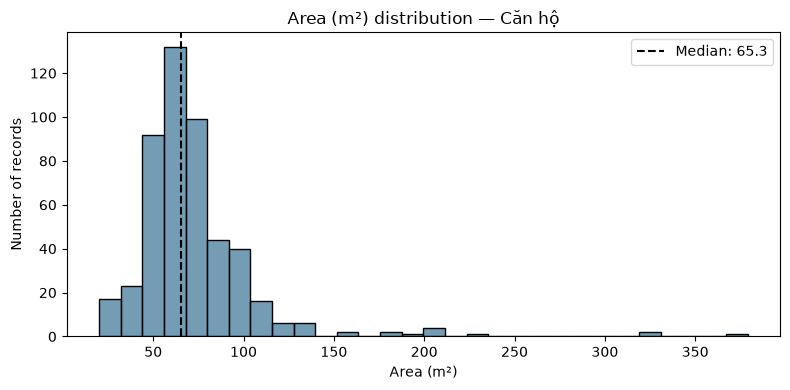

Five largest area (m²) records — Căn hộ


,listing_id,property_type,district,area,bedrooms,price_range
407,45011469,Căn hộ,Phường Cát Lái,379.0,6.0,23.9
367,45189772,Căn hộ,Phường Cát Lái,325.0,4.0,40.0
326,45209882,Căn hộ,Phường Cát Lái,325.0,4.0,44.9
443,44424655,Căn hộ,Phường Bình Trưng,229.7,4.0,31.0
302,41811080,Căn hộ,Phường An Khánh,202.0,4.0,48.0


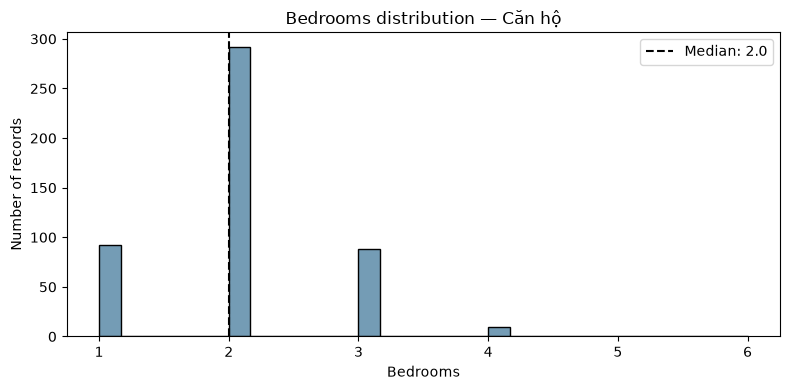

Five largest bedrooms records — Căn hộ


,listing_id,property_type,district,area,bedrooms,price_range
407,45011469,Căn hộ,Phường Cát Lái,379.0,6.0,23.9
234,43203408,Căn hộ,Phường An Khánh,201.0,4.0,45.0
443,44424655,Căn hộ,Phường Bình Trưng,229.7,4.0,31.0
302,41811080,Căn hộ,Phường An Khánh,202.0,4.0,48.0
367,45189772,Căn hộ,Phường Cát Lái,325.0,4.0,40.0


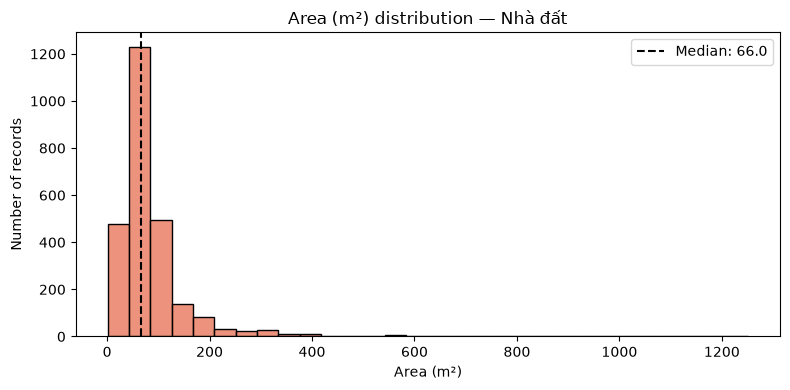

Five largest area (m²) records — Nhà đất


,listing_id,property_type,district,area,bedrooms,price_range
503,37920615,Nhà đất,Phường Chánh Phú Hòa,1251.0,55.0,16.26
790,45155867,Nhà đất,Phường An Hội Tây,859.9,NaN,46.00
1359,45152823,Nhà đất,Xã Tân Nhựt,678.0,22.0,31.00
2178,45050974,Nhà đất,Phường Tân Bình,656.0,8.0,159.00
527,45209347,Nhà đất,Phường Tăng Nhơn Phú,642.8,NaN,48.60


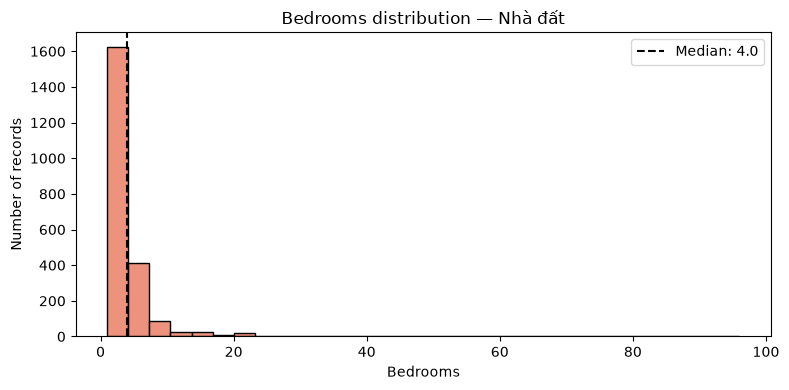

Five largest bedrooms records — Nhà đất


,listing_id,property_type,district,area,bedrooms,price_range
2457,45107518,Nhà đất,Phường Phú Thuận,1.144,96.0,140.00
2447,45109123,Nhà đất,Phường Tân Tạo,300.000,80.0,48.00
1113,44717979,Nhà đất,Phường Tân Bình,309.400,65.0,35.00
503,37920615,Nhà đất,Phường Chánh Phú Hòa,1251.000,55.0,16.26
2904,44752707,Nhà đất,Phường Vũng Tàu,293.100,50.0,90.00


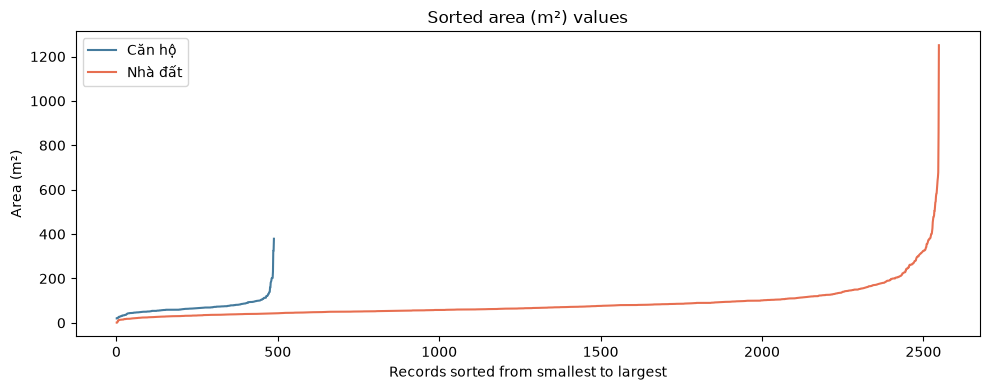

Five largest area (m²) records per property type


,listing_id,property_type,district,area,bedrooms,price_range
407,45011469,Căn hộ,Phường Cát Lái,379.0,6.0,23.90
326,45209882,Căn hộ,Phường Cát Lái,325.0,4.0,44.90
367,45189772,Căn hộ,Phường Cát Lái,325.0,4.0,40.00
443,44424655,Căn hộ,Phường Bình Trưng,229.7,4.0,31.00
64,44590405,Căn hộ,Phường An Khánh,202.0,4.0,60.00
503,37920615,Nhà đất,Phường Chánh Phú Hòa,1251.0,55.0,16.26
790,45155867,Nhà đất,Phường An Hội Tây,859.9,NaN,46.00
1359,45152823,Nhà đất,Xã Tân Nhựt,678.0,22.0,31.00
2178,45050974,Nhà đất,Phường Tân Bình,656.0,8.0,159.00
527,45209347,Nhà đất,Phường Tăng Nhơn Phú,642.8,NaN,48.60


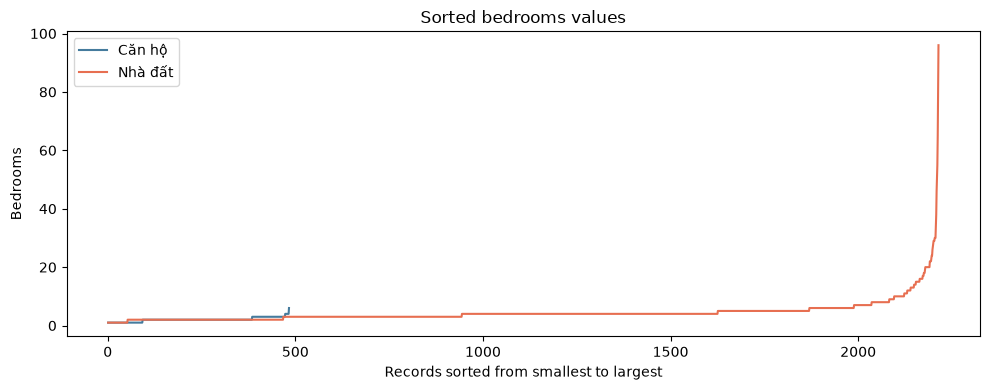

Five largest bedrooms records per property type


,listing_id,property_type,district,area,bedrooms,price_range
407,45011469,Căn hộ,Phường Cát Lái,379.000,6.0,23.90
64,44590405,Căn hộ,Phường An Khánh,202.000,4.0,60.00
67,39770672,Căn hộ,Phường An Khánh,202.000,4.0,50.00
234,43203408,Căn hộ,Phường An Khánh,201.000,4.0,45.00
302,41811080,Căn hộ,Phường An Khánh,202.000,4.0,48.00
2457,45107518,Nhà đất,Phường Phú Thuận,1.144,96.0,140.00
2447,45109123,Nhà đất,Phường Tân Tạo,300.000,80.0,48.00
1113,44717979,Nhà đất,Phường Tân Bình,309.400,65.0,35.00
503,37920615,Nhà đất,Phường Chánh Phú Hòa,1251.000,55.0,16.26
2904,44752707,Nhà đất,Phường Vũng Tàu,293.100,50.0,90.00


In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

record_columns = ["listing_id", "property_type", "district", "area", "bedrooms", "price_range"]
property_data = data[record_columns].copy()
property_data["area"] = pd.to_numeric(property_data["area"], errors="coerce")
property_data["bedrooms"] = pd.to_numeric(property_data["bedrooms"], errors="coerce")

summary = property_data.groupby("property_type")[["area", "bedrooms"]].agg(
    ["count", "median", "max"]
)
display(summary)

colors = {"Căn hộ": "#457b9d", "Nhà đất": "#e76f51"}
labels = {"area": "Area (m²)", "bedrooms": "Bedrooms"}

# Four separate histograms.
for property_type in property_data["property_type"].dropna().unique():
    for column in ["area", "bedrooms"]:
        values = property_data.loc[property_data["property_type"] == property_type, column].dropna()
        plt.figure(figsize=(8, 4))
        sns.histplot(values, bins=30, color=colors[property_type])
        plt.axvline(values.median(), color="black", linestyle="--", label=f"Median: {values.median():.1f}")
        plt.title(f"{labels[column]} distribution — {property_type}")
        plt.xlabel(labels[column])
        plt.ylabel("Number of records")
        plt.legend()
        plt.tight_layout()
        plt.show()

        graph_records = (
            property_data.loc[property_data["property_type"] == property_type]
            .dropna(subset=[column])
            .sort_values(column, ascending=False)
        )
        print(f"Five largest {labels[column].lower()} records — {property_type}")
        with pd.option_context("display.max_rows", len(graph_records), "display.max_columns", None):
            display(graph_records.head(5))

# Sorted values make sudden jumps at the upper end easy to identify.
for column in ["area", "bedrooms"]:
    plt.figure(figsize=(10, 4))
    for property_type in property_data["property_type"].dropna().unique():
        values = property_data.loc[property_data["property_type"] == property_type, column].dropna().sort_values().reset_index(drop=True)
        plt.plot(values.index + 1, values, label=property_type, color=colors[property_type])
    plt.title(f"Sorted {labels[column].lower()} values")
    plt.xlabel("Records sorted from smallest to largest")
    plt.ylabel(labels[column])
    plt.legend()
    plt.tight_layout()
    plt.show()

    graph_records = (
        property_data.dropna(subset=[column])
        .sort_values(["property_type", column], ascending=[True, False])
        .groupby("property_type", sort=False)
        .head(5)
    )
    print(f"Five largest {labels[column].lower()} records per property type")
    with pd.option_context("display.max_rows", len(graph_records), "display.max_columns", None):
        display(graph_records)

# 6. Records cleaned up by property-type outlier rules

In [50]:
from pathlib import Path
import pandas as pd
from IPython.display import display

APARTMENT_RULES = {
    "min_area": 30,       "max_area": 200,      # m2
    "min_beds": 1,        "max_beds": 4,        # bedrooms
    "min_price": 1.0,     "max_price": 15.0,    # billion VND
    "min_price_m2": 25,   "max_price_m2": 120,  # million VND / m2
}
HOUSE_RULES = {
    "min_area": 25,       "max_area": 350,      # m2
    "min_beds": 1,        "max_beds": 8,        # bedrooms
    "min_price": 1.5,     "max_price": 40.0,    # billion VND
    "min_price_m2": 35,   "max_price_m2": 350,  # million VND / m2
}

# Use Step 2 cleaned dataset if available, otherwise analyze from source data
clean_data_path = Path("step-2/cleaned_data.xlsx")
source_df = pd.read_excel(clean_data_path) if clean_data_path.exists() else data.copy()

display_cols = ["listing_id", "property_type", "district", "area", "bedrooms", "price_range", "price_per_m2"]


def get_outliers(df: pd.DataFrame, rules: dict) -> pd.DataFrame:
    """Identify records that fall outside the specified boundaries."""
    subset = df.copy()
    subset["area"] = pd.to_numeric(subset["area"], errors="coerce")
    subset["bedrooms"] = pd.to_numeric(subset["bedrooms"], errors="coerce")
    subset["price_range"] = pd.to_numeric(subset["price_range"], errors="coerce")
    subset["price_per_m2"] = (subset["price_range"] * 1000) / subset["area"]

    valid_mask = (
        subset["area"].between(rules["min_area"], rules["max_area"])
        & subset["bedrooms"].between(rules["min_beds"], rules["max_beds"])
        & subset["price_range"].between(rules["min_price"], rules["max_price"])
        & subset["price_per_m2"].between(rules["min_price_m2"], rules["max_price_m2"])
    )
    return subset.loc[~valid_mask, display_cols]


# Extract cleaned up records for both property types
cleaned_apts = get_outliers(source_df[source_df["property_type"] == "Căn hộ"], APARTMENT_RULES)
cleaned_houses = get_outliers(source_df[source_df["property_type"] == "Nhà đất"], HOUSE_RULES)
all_cleaned = pd.concat([cleaned_apts, cleaned_houses], ignore_index=True)

print(f"Total source records analyzed: {len(source_df):,}")
print(f"Cleaned apartment outliers:    {len(cleaned_apts):,} records")
print(f"Cleaned house/land outliers:   {len(cleaned_houses):,} records")
print(f"Total cleaned outlier records: {len(all_cleaned):,} ({len(all_cleaned) / len(source_df):.1%})\n")

print("Sample cleaned apartment records:")
with pd.option_context("display.max_rows", None):
    display(cleaned_apts.head(10))

print("Sample cleaned house/land records:")
with pd.option_context("display.max_rows", None):
    display(cleaned_houses.head(10))


Total source records analyzed: 2,662
Cleaned apartment outliers:    82 records
Cleaned house/land outliers:   350 records
Total cleaned outlier records: 432 (16.2%)

Sample cleaned apartment records:


,listing_id,property_type,district,area,bedrooms,price_range,price_per_m2
2,44850086,Căn hộ,Phường An Khánh,64.00,1,14.2,221.875000
3,45225431,Căn hộ,Phường Sài Gòn,87.00,2,32.1,368.965517
15,45102500,Căn hộ,Phường Thạnh Mỹ Tây,85.70,2,11.2,130.688448
24,44868190,Căn hộ,Phường Bến Thành,29.18,1,2.1,71.967101
26,42561310,Căn hộ,Phường An Khánh,138.00,3,25.0,181.159420
29,44742356,Căn hộ,Phường Vĩnh Hội,85.00,2,10.5,123.529412
31,44734124,Căn hộ,Phường An Khánh,64.00,1,11.3,176.562500
33,45149520,Căn hộ,Phường Thạnh Mỹ Tây,86.00,2,11.5,133.720930
38,45113783,Căn hộ,Phường Thạnh Mỹ Tây,86.00,2,12.0,139.534884
41,44333099,Căn hộ,Phường An Khánh,72.00,2,22.0,305.555556


Sample cleaned house/land records:


,listing_id,property_type,district,area,bedrooms,price_range,price_per_m2
470,37920615,Nhà đất,Phường Chánh Phú Hòa,1251.0,55,16.26,12.997602
472,45188401,Nhà đất,Phường Thới Hòa,150.0,2,2.90,19.333333
482,45221020,Nhà đất,Phường Hạnh Thông,183.8,4,72.00,391.730141
486,45164575,Nhà đất,Phường Long Hương,325.0,16,16.00,49.230769
487,45233274,Nhà đất,Phường Bình Tân,312.1,16,24.97,80.006408
488,44945202,Nhà đất,Phường Cát Lái,466.8,5,115.00,246.358183
491,45232003,Nhà đất,Phường Bình Thạnh,76.2,13,12.80,167.979003
493,44960303,Nhà đất,Phường Vườn Lài,21.0,3,4.35,207.142857
497,44869380,Nhà đất,Phường Tân Thới Hiệp,100.0,14,9.98,99.800000
499,45195893,Nhà đất,Phường Hòa Hưng,15.0,3,3.68,245.333333


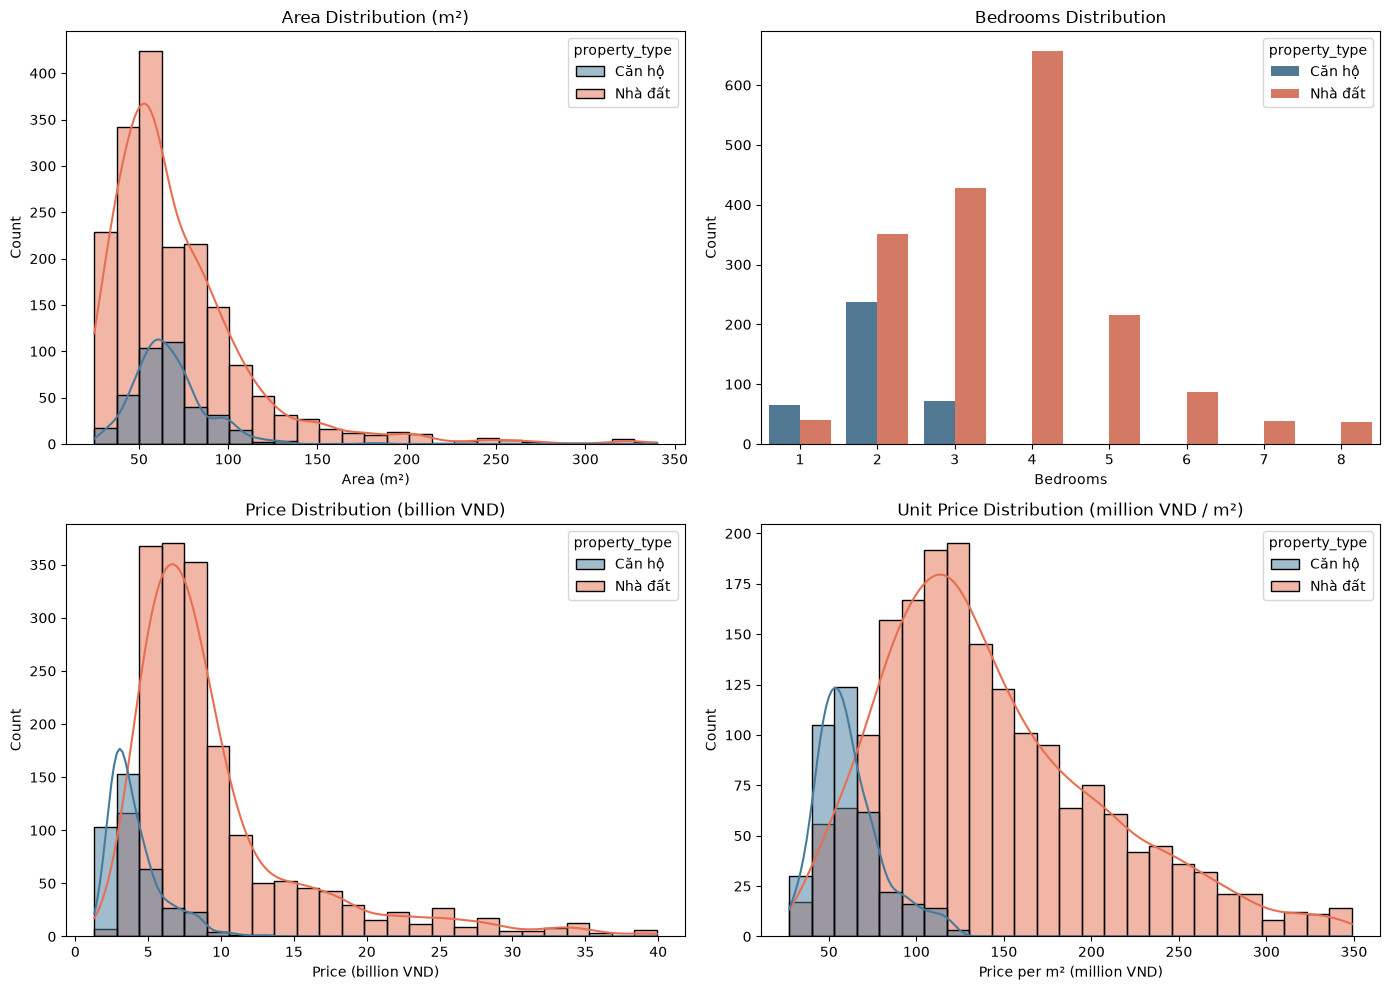

Total clean records: 2,230 (Căn hộ: 376, Nhà đất: 1,854)


area              bedrooms         price_range             \
              median   min    max   median min max      median  min   max   
property_type                                                               
Căn hộ         64.00  30.0  181.0      2.0   1   3         3.5  1.3  13.0   
Nhà đất        60.05  25.0  340.0      4.0   1   8         7.6  2.1  39.9   

              price_per_m2                         
                    median        min         max  
property_type                                      
Căn hộ           57.427108  27.500000  119.402985  
Nhà đất         128.260870  35.874439  348.837209

In [51]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filter clean records within rules for each property type
def get_clean_data(df: pd.DataFrame, rules: dict) -> pd.DataFrame:
    subset = df.copy()
    subset["area"] = pd.to_numeric(subset["area"], errors="coerce")
    subset["bedrooms"] = pd.to_numeric(subset["bedrooms"], errors="coerce")
    subset["price_range"] = pd.to_numeric(subset["price_range"], errors="coerce")
    subset["price_per_m2"] = (subset["price_range"] * 1000) / subset["area"]

    valid_mask = (
        subset["area"].between(rules["min_area"], rules["max_area"])
        & subset["bedrooms"].between(rules["min_beds"], rules["max_beds"])
        & subset["price_range"].between(rules["min_price"], rules["max_price"])
        & subset["price_per_m2"].between(rules["min_price_m2"], rules["max_price_m2"])
    )
    return subset.loc[valid_mask]


clean_apts = get_clean_data(source_df[source_df["property_type"] == "Căn hộ"], APARTMENT_RULES)
clean_houses = get_clean_data(source_df[source_df["property_type"] == "Nhà đất"], HOUSE_RULES)
clean_df = pd.concat([clean_apts, clean_houses], ignore_index=True)

# 2x2 grid visualizing key features after outlier cleanup
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
colors = {"Căn hộ": "#457b9d", "Nhà đất": "#e76f51"}

# 1. Area distribution
sns.histplot(data=clean_df, x="area", hue="property_type", palette=colors, kde=True, ax=axes[0, 0], bins=25)
axes[0, 0].set_title("Area Distribution (m²)")
axes[0, 0].set_xlabel("Area (m²)")
axes[0, 0].set_ylabel("Count")

# 2. Bedrooms distribution
sns.countplot(data=clean_df, x="bedrooms", hue="property_type", palette=colors, ax=axes[0, 1])
axes[0, 1].set_title("Bedrooms Distribution")
axes[0, 1].set_xlabel("Bedrooms")
axes[0, 1].set_ylabel("Count")

# 3. Price distribution
sns.histplot(data=clean_df, x="price_range", hue="property_type", palette=colors, kde=True, ax=axes[1, 0], bins=25)
axes[1, 0].set_title("Price Distribution (billion VND)")
axes[1, 0].set_xlabel("Price (billion VND)")
axes[1, 0].set_ylabel("Count")

# 4. Unit price distribution
sns.histplot(data=clean_df, x="price_per_m2", hue="property_type", palette=colors, kde=True, ax=axes[1, 1], bins=25)
axes[1, 1].set_title("Unit Price Distribution (million VND / m²)")
axes[1, 1].set_xlabel("Price per m² (million VND)")
axes[1, 1].set_ylabel("Count")

plt.tight_layout()
plt.show()

print(f"Total clean records: {len(clean_df):,} (Căn hộ: {len(clean_apts):,}, Nhà đất: {len(clean_houses):,})")
summary_stats = clean_df.groupby("property_type")[["area", "bedrooms", "price_range", "price_per_m2"]].agg(["median", "min", "max"])
display(summary_stats)
